In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

In [2]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

El equipo ha dado tres estimaciones de la duración de cada actividad (optimista $a$, más probable $m$ y pesimista $b$, en semanas). Para las actividades B y A se extravió la estimación optimista, pero se conserva la duración media que se había calculado.

In [3]:
pregunta_1 = "1. Calcule la duración media y la varianza de cada actividad según el método PERT.  "
pregunta_2 = "2. Recupere la estimación optimista de B y A a partir de su duración media.  "
pregunta_3 = "3. Dibuje el grafo PERT, determine el camino crítico con las duraciones medias y la duración media del proyecto. ¿Qué papel juegan las estimaciones optimista y pesimista en ese cálculo?  "
pregunta_4 = "4. Para la actividad G, compare la media y la desviación típica que resultan de suponer una distribución Beta-PERT, una triangular y una uniforme con los mismos valores extremos. ¿Cuál es más prudente?  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Calcule la duración media y la varianza de cada actividad según el método PERT.  

2. Recupere la estimación optimista de B y A a partir de su duración media.  

3. Dibuje el grafo PERT, determine el camino crítico con las duraciones medias y la duración media del proyecto. ¿Qué papel juegan las estimaciones optimista y pesimista en ese cálculo?  

4. Para la actividad G, compare la media y la desviación típica que resultan de suponer una distribución Beta-PERT, una triangular y una uniforme con los mismos valores extremos. ¿Cuál es más prudente?  

In [4]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, a  , m, b , duration
    ('A'     , '---'      , '?', 3, 5 , 3       ),
    ('B'     , '---'      , '?', 6, 8 , 6       ),
    ('C'     , 'A'        , 1  , 3, 5 , '?'     ),
    ('D'     , 'C'        , 6  , 8, 10, '?'     ),
    ('E'     , 'B,D'      , 3  , 9, 9 , '?'     ),
    ('F'     , 'B,C'      , 3  , 6, 9 , '?'     ),
    ('G'     , 'E,F'      , 4  , 4, 10, '?'     ),
], columns=['activity', 'predecessor', 'a', 'm', 'b', 'duration']).set_index('activity')
datos_enunciado

,predecessor,a,m,b,duration
activity,,,,,
A,---,?,3,5,3
B,---,?,6,8,6
C,A,1,3,5,?
D,C,6,8,10,?
E,"B,D",3,9,9,?
F,"B,C",3,6,9,?
G,"E,F",4,4,10,?


# Resolución

## Apartado 1

In [5]:
display(Markdown(pregunta_1))

1. Calcule la duración media y la varianza de cada actividad según el método PERT.  

El método PERT supone que la duración sigue una distribución Beta cuya media y varianza se aproximan por

$$D = \frac{a + 4m + b}{6}, \qquad \sigma^2 = \left(\frac{b - a}{6}\right)^2.$$

In [6]:
datos_proyecto = datos_enunciado.copy()
conocidas = datos_proyecto['a'] != '?'
numericas = datos_proyecto.loc[conocidas, ['a', 'm', 'b']].astype(float)
datos_proyecto.loc[conocidas, 'duration'] = numericas.eval('(a + 4 * m + b) / 6')
datos_proyecto.loc[conocidas, 'variance'] = numericas.eval('((b - a) / 6) ** 2')
datos_proyecto

,predecessor,a,m,b,duration,variance
activity,,,,,,
A,---,?,3,5,3,NaN
B,---,?,6,8,6,NaN
C,A,1,3,5,3.0,0.444444
D,C,6,8,10,8.0,0.444444
E,"B,D",3,9,9,8.0,1.000000
F,"B,C",3,6,9,6.0,1.000000
G,"E,F",4,4,10,5.0,1.000000


## Apartado 2

In [7]:
display(Markdown(pregunta_2))

2. Recupere la estimación optimista de B y A a partir de su duración media.  

Despejando en la fórmula de la media: $a = 6D - 4m - b$.

In [8]:
faltan = ~conocidas
datos_proyecto.loc[faltan, 'a'] = (6 * datos_proyecto.loc[faltan, 'duration'].astype(float)
                                   - 4 * datos_proyecto.loc[faltan, 'm'].astype(float)
                                   - datos_proyecto.loc[faltan, 'b'].astype(float))
datos_proyecto[['a', 'm', 'b', 'duration']] = datos_proyecto[['a', 'm', 'b', 'duration']].astype(float)
datos_proyecto['variance'] = datos_proyecto.eval('((b - a) / 6) ** 2')
datos_proyecto['standard_deviation'] = np.sqrt(datos_proyecto['variance'])
datos_proyecto.loc[faltan, ['a', 'm', 'b', 'duration', 'variance']]

,a,m,b,duration,variance
activity,,,,,
A,1.0,3.0,5.0,3.0,0.444444
B,4.0,6.0,8.0,6.0,0.444444


## Apartado 3

In [9]:
display(Markdown(pregunta_3))

3. Dibuje el grafo PERT, determine el camino crítico con las duraciones medias y la duración media del proyecto. ¿Qué papel juegan las estimaciones optimista y pesimista en ese cálculo?  

In [10]:
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
duraciones = datos_proyecto['duration'].round().astype(int)

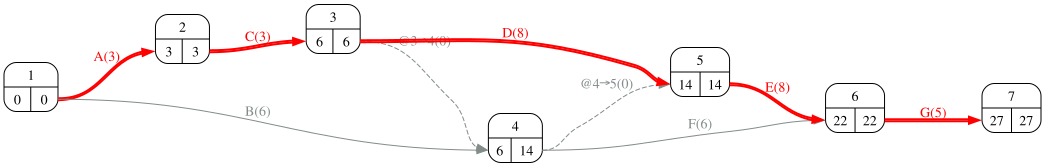

In [11]:
#| fig-cap: "Grafo PERT con las duraciones medias y el camino crítico"
#| label: fig-pert
proyecto.pert(durations=duraciones, ranksep=1)

In [12]:
duracion_proyecto = proyecto.duration(duraciones)
camino_critico = proyecto.display_critical_path(duraciones)
Markdown(f'La duración media del proyecto es {duracion_proyecto} semanas. Las estimaciones optimista y pesimista '
         'no intervienen directamente en el camino crítico: sólo a través de la media de cada actividad. '
         'Donde sí cuentan es en la varianza, y por tanto en la probabilidad de cumplir un plazo.')

- Route_1 :	A, C, D, E, G <br> 

La duración media del proyecto es 27 semanas. Las estimaciones optimista y pesimista no intervienen directamente en el camino crítico: sólo a través de la media de cada actividad. Donde sí cuentan es en la varianza, y por tanto en la probabilidad de cumplir un plazo.

## Apartado 4

In [13]:
display(Markdown(pregunta_4))

4. Para la actividad G, compare la media y la desviación típica que resultan de suponer una distribución Beta-PERT, una triangular y una uniforme con los mismos valores extremos. ¿Cuál es más prudente?  

Con los mismos extremos $a$ y $b$ (y la misma moda $m$ en la triangular):

| Distribución | Media | Varianza |
|---|---|---|
| Beta-PERT | $(a + 4m + b)/6$ | $((b-a)/6)^2$ |
| Triangular | $(a + m + b)/3$ | $(a^2 + m^2 + b^2 - ab - am - bm)/18$ |
| Uniforme | $(a + b)/2$ | $(b-a)^2/12$ |

In [14]:
a_, m_, b_ = datos_proyecto.loc['G', ['a', 'm', 'b']]
comparacion = pd.DataFrame({
    'Beta-PERT':  [(a_ + 4 * m_ + b_) / 6, ((b_ - a_) / 6) ** 2],
    'Triangular': [(a_ + m_ + b_) / 3, (a_**2 + m_**2 + b_**2 - a_*b_ - a_*m_ - b_*m_) / 18],
    'Uniforme':   [(a_ + b_) / 2, (b_ - a_) ** 2 / 12]},
    index=['media', 'varianza'])
comparacion.loc['desviación típica'] = np.sqrt(comparacion.loc['varianza'])
comparacion.round(3)

,Beta-PERT,Triangular,Uniforme
media,5.0,6.000,7.000
varianza,1.0,2.000,3.000
desviación típica,1.0,1.414,1.732


In [15]:
Markdown(f'''La Beta-PERT concentra la probabilidad cerca de la moda ({m_:.0f}) y por eso tiene la menor varianza; la uniforme reparte la probabilidad por igual entre {a_:.0f} y {b_:.0f} y es la más dispersa; la triangular queda en medio. Cuando la moda no está centrada, las medias también difieren: la PERT pesa la moda cuatro veces y se queda más cerca de ella. La uniforme es la hipótesis más prudente (mayor varianza), pero sólo está justificada si de verdad no se sabe nada entre los extremos.''')

La Beta-PERT concentra la probabilidad cerca de la moda (4) y por eso tiene la menor varianza; la uniforme reparte la probabilidad por igual entre 4 y 10 y es la más dispersa; la triangular queda en medio. Cuando la moda no está centrada, las medias también difieren: la PERT pesa la moda cuatro veces y se queda más cerca de ella. La uniforme es la hipótesis más prudente (mayor varianza), pero sólo está justificada si de verdad no se sabe nada entre los extremos.